# лабораторная работа 8 - ассоциативные правила
ищем товары, которые часто покупают вместе в одной корзине
данные - ai_market_basket_lab8.csv, вариант 3 - фильтр lift > 1.20

## загрузка данных
каждая строка файла - пара транзакция и товар
названия товаров переводим в нижний регистр

In [1]:
import csv
import os

candidates = ["ai_market_basket_lab8.csv", "../ai_market_basket_lab8.csv", "C:/ai_market_basket_lab8.csv"]
data_path = ""
for path in candidates:
    if os.path.exists(path):
        data_path = path
        break

if data_path == "":
    raise FileNotFoundError("положите ai_market_basket_lab8.csv рядом с ноутбуком")

rows = []
with open(data_path, encoding="utf-8-sig") as file:
    for row in csv.reader(file):
        rows.append([row[0], row[1].lower()])

header = rows[0]
rows = rows[1:]
print(f"файл: {data_path}")
print(f"столбцы: {header[0]} и {header[1]}")
print(f"строк с товарами: {len(rows)}")
print("-" * 55)
for row in rows[:5]:
    print(f"{row[0]:>5}  {row[1]}")

файл: ai_market_basket_lab8.csv
столбцы: TransactionId и product
строк с товарами: 939
-------------------------------------------------------
    1  йогурт
    1  молоко
    1  яйца
    2  бананы
    2  масло


## корзины покупок
объект наблюдения - транзакция, то есть одна корзина
товар - это бинарный признак корзины

In [2]:
basket_map = {}
for row in rows:
    transaction_id = row[0]
    product = row[1]
    if transaction_id not in basket_map:
        basket_map[transaction_id] = []
    basket_map[transaction_id].append(product)

baskets = []
for transaction_id in sorted(basket_map, key=int):
    baskets.append(basket_map[transaction_id])

print(f"корзин: {len(baskets)}")
print(f"средняя длина корзины: {len(rows) / len(baskets):.2f}")
print("-" * 55)
for i in range(10):
    print(f"{i:>2}: {baskets[i]}")

max_length = 0
for basket in baskets:
    if len(basket) > max_length:
        max_length = len(basket)
print(f"самая длинная корзина: {max_length} товаров")

корзин: 300
средняя длина корзины: 3.13
-------------------------------------------------------
 0: ['йогурт', 'молоко', 'яйца']
 1: ['бананы', 'масло', 'сахар', 'хлеб']
 2: ['молоко', 'хлеб']
 3: ['йогурт', 'молоко', 'печенье', 'сахар']
 4: ['кофе', 'сахар', 'чай']
 5: ['масло', 'молоко', 'хлеб']
 6: ['йогурт', 'масло', 'хлеб', 'яйца']
 7: ['масло', 'сахар', 'хлеб']
 8: ['сыр']
 9: ['йогурт', 'молоко', 'яйца']
самая длинная корзина: 7 товаров


## популярность товаров
частые товары сами по себе еще не дают правил
важна совместная встречаемость в одной корзине

In [3]:
products = []
for basket in baskets:
    for product in basket:
        if product not in products:
            products.append(product)
products = sorted(products)

single_counts = {}
for product in products:
    count = 0
    for basket in baskets:
        if product in basket:
            count += 1
    single_counts[(product,)] = count

order = []
for product in products:
    order.append((single_counts[(product,)], product))
order = sorted(order, reverse=True)

print(f"{'товар':<10} {'корзин':>7} {'доля':>8}")
print("-" * 55)
for count, product in order:
    share = count / len(baskets) * 100
    print(f"{product:<10} {count:>7} {share:>7.2f}%")

товар       корзин     доля
-------------------------------------------------------
хлеб           113   37.67%
молоко         106   35.33%
йогурт         102   34.00%
масло           97   32.33%
печенье         87   29.00%
сахар           79   26.33%
яйца            72   24.00%
яблоки          68   22.67%
кофе            63   21.00%
чай             52   17.33%
бананы          52   17.33%
сыр             48   16.00%


## график популярности
столбец - число корзин, где встречается товар

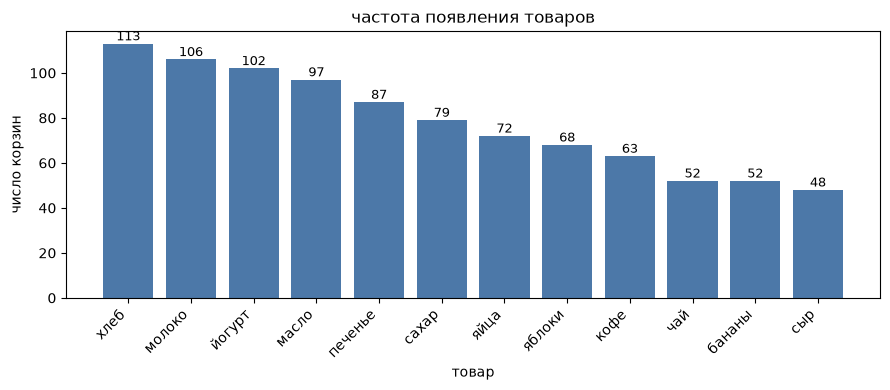

In [17]:
import matplotlib.pyplot as plt

names = []
counts = []
for count, product in order:
    names.append(product)
    counts.append(count)

plt.figure(figsize=(9, 4))
plt.bar(names, counts, color="#4c78a8")
for i in range(len(names)):
    plt.text(i, counts[i] + 1.5, str(counts[i]), ha="center", fontsize=9)
plt.title("частота появления товаров")
plt.xlabel("товар")
plt.ylabel("число корзин")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## one-hot матрица
строка - корзина, столбец - товар
1 значит товар есть в корзине

In [4]:
import numpy as np

matrix = np.zeros((len(baskets), len(products)), dtype=int)
for i in range(len(baskets)):
    for j in range(len(products)):
        if products[j] in baskets[i]:
            matrix[i][j] = 1

print(f"размер матрицы: {matrix.shape}")
print("-" * 55)
for j in range(len(products)):
    print(f"{products[j]:<9}", end="")
print()
for i in range(3):
    for j in range(len(products)):
        print(f"{matrix[i][j]:<9}", end="")
    print()

restored = []
for j in range(len(products)):
    if matrix[0][j] == 1:
        restored.append(products[j])
print(f"строка 0: {restored}")
if restored == sorted(baskets[0]):
    print("совпадает с корзиной: да")
else:
    print("совпадает с корзиной: нет")

размер матрицы: (300, 12)
-------------------------------------------------------
бананы   йогурт   кофе     масло    молоко   печенье  сахар    сыр      хлеб     чай      яблоки   яйца     
0        1        0        0        1        0        0        0        0        0        0        1        
1        0        0        1        0        0        1        0        1        0        0        0        
0        0        0        0        1        0        0        0        1        0        0        0        
строка 0: ['йогурт', 'молоко', 'яйца']
совпадает с корзиной: да


## support и частые наборы
support = корзины с набором / все корзины
набор частый если support >= 0.08

In [5]:
def contains_all(basket, items):
    for item in items:
        if item not in basket:
            return False
    return True


def count_support(baskets, items):
    count = 0
    for basket in baskets:
        if contains_all(basket, items):
            count += 1
    return count


def frequent_items(counts, min_support):
    result = []
    for items in counts:
        if counts[items] / len(baskets) >= min_support:
            result.append(items)
    return result


total = len(baskets)
print(f"всего корзин: {total}")
print(f"support хлеба: {single_counts[('хлеб',)] / total:.4f}")

всего корзин: 300
support хлеба: 0.3767


## частые пары и тройки
идея apriori - редкая пара не входит в частую тройку
поэтому тройки собираем только из частых пар

In [6]:
frequent_singles = frequent_items(single_counts, 0.08)

pair_counts = {}
for i in range(len(frequent_singles)):
    for j in range(i + 1, len(frequent_singles)):
        items = (frequent_singles[i][0], frequent_singles[j][0])
        pair_counts[items] = count_support(baskets, items)
frequent_pairs = frequent_items(pair_counts, 0.08)

triple_counts = {}
for pair in frequent_pairs:
    for single in frequent_singles:
        product = single[0]
        if product not in pair:
            items = tuple(sorted([pair[0], pair[1], product]))
            if items not in triple_counts:
                triple_counts[items] = count_support(baskets, items)
frequent_triples = frequent_items(triple_counts, 0.08)

frequent_all = frequent_singles + frequent_pairs + frequent_triples
print(f"одиночных: {len(frequent_singles)}, пар: {len(frequent_pairs)}, троек: {len(frequent_triples)}")
print(f"всего частых наборов: {len(frequent_all)}")
print("-" * 55)
for items in frequent_triples:
    print(f"{items} support = {triple_counts[items] / total:.4f}")

одиночных: 12, пар: 19, троек: 2
всего частых наборов: 33
-------------------------------------------------------
('йогурт', 'молоко', 'печенье') support = 0.0800
('масло', 'молоко', 'хлеб') support = 0.0800


## confidence и lift
confidence = support(a и b) / support(a)
lift = confidence / support(b)
lift > 1 - совместная встречаемость выше ожидаемой

In [7]:
def make_rule(a_items, b_items, count_ab):
    count_a = count_support(baskets, a_items)
    count_b = count_support(baskets, b_items)
    confidence = count_ab / count_a
    lift = confidence / (count_b / total)
    return {"a": a_items, "b": b_items, "support": count_ab / total, "confidence": confidence, "lift": lift}


all_rules = []
for pair in frequent_pairs:
    a_items = (pair[0],)
    b_items = (pair[1],)
    all_rules.append(make_rule(a_items, b_items, pair_counts[pair]))
    all_rules.append(make_rule(b_items, a_items, pair_counts[pair]))

print(f"правил из пар: {len(all_rules)}")

правил из пар: 38


## график confidence против lift
размер точки - support, красная линия - lift = 1

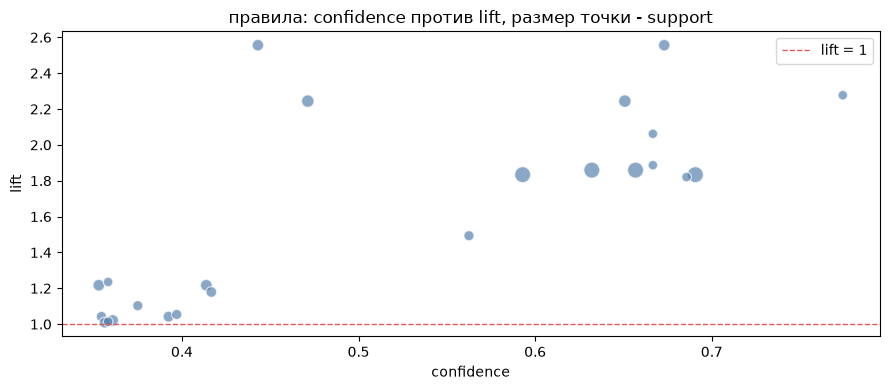

In [18]:
import matplotlib.pyplot as plt

confidences = []
lifts = []
sizes = []
for rule in rules:
    confidences.append(rule["confidence"])
    lifts.append(rule["lift"])
    sizes.append(rule["support"] * 600)

plt.figure(figsize=(9, 4))
plt.scatter(confidences, lifts, s=sizes, alpha=0.65, color="#4c78a8", edgecolor="white")
plt.axhline(1.0, color="#e45756", linestyle="--", linewidth=1, label="lift = 1")
plt.xlabel("confidence")
plt.ylabel("lift")
plt.title("правила: confidence против lift, размер точки - support")
plt.legend()
plt.tight_layout()
plt.show()

## правила из троек
из тройки получаем правила с одним товаром и с парой в условии
оставляем правила с confidence >= 0.35

In [8]:
def other_items(items, skip):
    result = []
    for item in items:
        if item != skip:
            result.append(item)
    return result


for triple in frequent_triples:
    for item in triple:
        rest = tuple(other_items(triple, item))
        all_rules.append(make_rule((item,), rest, triple_counts[triple]))
        all_rules.append(make_rule(rest, (item,), triple_counts[triple]))

rules = []
for rule in all_rules:
    if rule["confidence"] >= 0.35:
        rules.append(rule)

print(f"правил-кандидатов: {len(all_rules)}")
print(f"правил с confidence >= 0.35: {len(rules)}")

правил-кандидатов: 50
правил с confidence >= 0.35: 24


## таблица правил
правило читается как если в корзине есть a, то часто есть b

In [9]:
print(f"{'если':<22} {'то':<14} {'support':>8} {'conf':>7} {'lift':>7}")
print("-" * 55)
for rule in rules:
    a_text = " + ".join(rule["a"])
    b_text = " + ".join(rule["b"])
    print(f"{a_text:<22} {b_text:<14} {rule['support']:>8.3f} {rule['confidence']:>7.3f} {rule['lift']:>7.3f}")

lift_values = np.zeros(len(rules))
for i in range(len(rules)):
    lift_values[i] = rules[i]["lift"]
best = rules[np.argmax(lift_values)]
print("-" * 55)
print(f"самый сильный lift: {best['lift']:.3f}")
print(f"правило: {' + '.join(best['a'])} -> {' + '.join(best['b'])}")

если                   то              support    conf    lift
-------------------------------------------------------
йогурт                 молоко            0.223   0.657   1.859
молоко                 йогурт            0.223   0.632   1.859
йогурт                 печенье           0.120   0.353   1.217
печенье                йогурт            0.120   0.414   1.217
сахар                  йогурт            0.093   0.354   1.042
яйца                   йогурт            0.090   0.375   1.103
кофе                   печенье           0.137   0.651   2.244
печенье                кофе              0.137   0.471   2.244
масло                  молоко            0.117   0.361   1.021
масло                  хлеб              0.223   0.691   1.834
хлеб                   масло             0.223   0.593   1.834
печенье                молоко            0.103   0.356   1.008
яйца                   молоко            0.100   0.417   1.179
сахар                  хлеб              0.103   0.392   1.042

## полезные правила
полезное правило - support >= 0.08, confidence >= 0.45, lift > 1.10

In [10]:
useful_rules = []
for rule in rules:
    good_support = rule["support"] >= 0.08
    good_confidence = rule["confidence"] >= 0.45
    good_lift = rule["lift"] > 1.10
    if good_support and good_confidence and good_lift:
        useful_rules.append(rule)

print(f"полезных правил: {len(useful_rules)}")
print("-" * 55)
for rule in useful_rules:
    a_text = " + ".join(rule["a"])
    b_text = " + ".join(rule["b"])
    print(f"{a_text:<22} {b_text:<14} conf = {rule['confidence']:.3f}  lift = {rule['lift']:.3f}")

полезных правил: 12
-------------------------------------------------------
йогурт                 молоко         conf = 0.657  lift = 1.859
молоко                 йогурт         conf = 0.632  lift = 1.859
кофе                   печенье        conf = 0.651  lift = 2.244
печенье                кофе           conf = 0.471  lift = 2.244
масло                  хлеб           conf = 0.691  lift = 1.834
хлеб                   масло          conf = 0.593  lift = 1.834
чай                    сахар          conf = 0.673  lift = 2.556
сыр                    хлеб           conf = 0.562  lift = 1.493
молоко + печенье       йогурт         conf = 0.774  lift = 2.277
йогурт + печенье       молоко         conf = 0.667  lift = 1.887
молоко + хлеб          масло          conf = 0.667  lift = 2.062
масло + молоко         хлеб           conf = 0.686  lift = 1.820


## рекомендация к товару
берем лучшее по lift правило с одним товаром в условии
это не персональная система - история покупателя не используется

In [11]:
def recommend(product, rules):
    best_rule = None
    for rule in rules:
        if rule["a"] == (product,) and len(rule["b"]) == 1:
            if best_rule is None or rule["lift"] > best_rule["lift"]:
                best_rule = rule
    return best_rule


def recommend_name(product, rules):
    rule = recommend(product, rules)
    if rule is None:
        return "нет"
    return rule["b"][0]


print(f"{'товар':<10} {'рекомендация':<12}")
print("-" * 55)
for product in products:
    print(f"{product:<10} {recommend_name(product, useful_rules):<12}")

товар      рекомендация
-------------------------------------------------------
бананы     нет         
йогурт     молоко      
кофе       печенье     
масло      хлеб        
молоко     йогурт      
печенье    кофе        
сахар      нет         
сыр        хлеб        
хлеб       масло       
чай        сахар       
яблоки     нет         
яйца       нет         


## confidence против lift
у масло -> хлеб и чай -> сахар похожая confidence
но lift выше у чай -> сахар, а охват шире у масло -> хлеб

In [12]:
rule_butter = None
rule_tea = None
for rule in rules:
    if rule["a"] == ("масло",) and rule["b"] == ("хлеб",):
        rule_butter = rule
    if rule["a"] == ("чай",) and rule["b"] == ("сахар",):
        rule_tea = rule

print(f"{'правило':<20} {'support':>8} {'conf':>7} {'lift':>7}")
print("-" * 55)
for rule in [rule_butter, rule_tea]:
    text = " + ".join(rule["a"]) + " -> " + " + ".join(rule["b"])
    print(f"{text:<20} {rule['support']:>8.3f} {rule['confidence']:>7.3f} {rule['lift']:>7.3f}")

правило               support    conf    lift
-------------------------------------------------------
масло -> хлеб           0.223   0.691   1.834
чай -> сахар            0.117   0.673   2.556


## влияние min_support
чем выше порог, тем меньше наборов и правил
низкий порог дает больше редких и случайных связей

In [20]:
all_triple_counts = {}
for i in range(len(products)):
    for j in range(i + 1, len(products)):
        for k in range(j + 1, len(products)):
            items = (products[i], products[j], products[k])
            all_triple_counts[items] = count_support(baskets, items)

support_levels = [0.05, 0.08, 0.15]
itemset_totals = []
rule_totals = []
for min_support in support_levels:
    singles = frequent_items(single_counts, min_support)
    pairs = frequent_items(pair_counts, min_support)
    triples = frequent_items(all_triple_counts, min_support)
    candidates = []
    for pair in pairs:
        candidates.append(make_rule((pair[0],), (pair[1],), pair_counts[pair]))
        candidates.append(make_rule((pair[1],), (pair[0],), pair_counts[pair]))
    for triple in triples:
        for item in triple:
            rest = tuple(other_items(triple, item))
            candidates.append(make_rule((item,), rest, all_triple_counts[triple]))
            candidates.append(make_rule(rest, (item,), all_triple_counts[triple]))
    good_count = 0
    for rule in candidates:
        if rule["confidence"] >= 0.35:
            good_count += 1
    itemset_totals.append(len(singles) + len(pairs) + len(triples))
    rule_totals.append(good_count)

## график влияния min_support
сравниваем число наборов и правил на трех порогах

 порог   наборов   правил
-------------------------------------------------------
  0.05        66       47
  0.08        33       24
  0.15        14        4


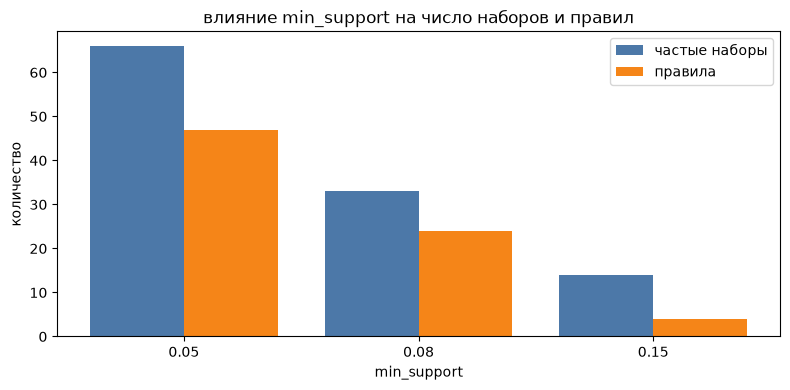

In [21]:
import matplotlib.pyplot as plt

print(f"{'порог':>6} {'наборов':>9} {'правил':>8}")
print("-" * 55)
for i in range(len(support_levels)):
    print(f"{support_levels[i]:>6.2f} {itemset_totals[i]:>9} {rule_totals[i]:>8}")

left = []
right = []
for i in range(len(support_levels)):
    left.append(i - 0.2)
    right.append(i + 0.2)

plt.figure(figsize=(8, 4))
plt.bar(left, itemset_totals, width=0.4, label="частые наборы", color="#4c78a8")
plt.bar(right, rule_totals, width=0.4, label="правила", color="#f58518")
plt.xticks([0, 1, 2], ["0.05", "0.08", "0.15"])
plt.xlabel("min_support")
plt.ylabel("количество")
plt.title("влияние min_support на число наборов и правил")
plt.legend()
plt.tight_layout()
plt.show()

## вариант 3 - фильтр lift > 1.20
оставляем только правила с lift > 1.20
потери - слабые связи с lift чуть выше 1

In [14]:
strong_rules = []
lost_rules = []
for rule in rules:
    if rule["lift"] > 1.20:
        strong_rules.append(rule)
    else:
        lost_rules.append(rule)

print(f"правил всего: {len(rules)}")
print(f"осталось с lift > 1.20: {len(strong_rules)}")
print(f"потеряно: {len(lost_rules)}")
print(f"доля сохраненных: {len(strong_rules) / len(rules) * 100:.1f}%")
print("-" * 55)
print(f"{'потерянное правило':<34} {'conf':>7} {'lift':>7}")
for rule in lost_rules:
    text = " + ".join(rule["a"]) + " -> " + " + ".join(rule["b"])
    print(f"{text:<34} {rule['confidence']:>7.3f} {rule['lift']:>7.3f}")

правил всего: 24
осталось с lift > 1.20: 16
потеряно: 8
доля сохраненных: 66.7%
-------------------------------------------------------
потерянное правило                    conf    lift
сахар -> йогурт                      0.354   1.042
яйца -> йогурт                       0.375   1.103
масло -> молоко                      0.361   1.021
печенье -> молоко                    0.356   1.008
яйца -> молоко                       0.417   1.179
сахар -> хлеб                        0.392   1.042
яблоки -> хлеб                       0.397   1.054
масло + хлеб -> молоко               0.358   1.014


## график фильтра по lift
видно сколько правил и полезных правил остается на разных порогах

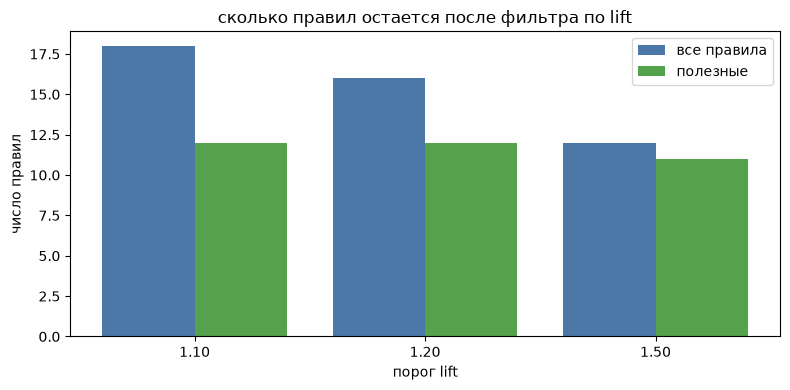

In [22]:
import matplotlib.pyplot as plt

lift_levels = [1.10, 1.20, 1.50]
all_kept = []
useful_kept = []
for level in lift_levels:
    count_all = 0
    count_useful = 0
    for rule in rules:
        if rule["lift"] > level:
            count_all += 1
    for rule in useful_rules:
        if rule["lift"] > level:
            count_useful += 1
    all_kept.append(count_all)
    useful_kept.append(count_useful)

left = []
right = []
for i in range(len(lift_levels)):
    left.append(i - 0.2)
    right.append(i + 0.2)

plt.figure(figsize=(8, 4))
plt.bar(left, all_kept, width=0.4, label="все правила", color="#4c78a8")
plt.bar(right, useful_kept, width=0.4, label="полезные", color="#54a24b")
plt.xticks([0, 1, 2], ["1.10", "1.20", "1.50"])
plt.xlabel("порог lift")
plt.ylabel("число правил")
plt.title("сколько правил остается после фильтра по lift")
plt.legend()
plt.tight_layout()
plt.show()

## что потерял фильтр
для яблок и яиц рекомендации исчезают совсем
все полезные правила сохраняются - их lift >= 1.49

In [15]:
print(f"{'товар':<10} {'все правила':<14} {'lift > 1.20':<14}")
print("-" * 55)
lost_products = []
for product in products:
    name_all = recommend_name(product, rules)
    name_strong = recommend_name(product, strong_rules)
    print(f"{product:<10} {name_all:<14} {name_strong:<14}")
    if name_all != "нет" and name_strong == "нет":
        lost_products.append(product)
print("-" * 55)
print(f"остались без рекомендаций: {lost_products}")

kept_useful = 0
for rule in useful_rules:
    if rule["lift"] > 1.20:
        kept_useful += 1
print(f"полезных правил сохранено: {kept_useful} из {len(useful_rules)}")

товар      все правила    lift > 1.20   
-------------------------------------------------------
бананы     нет            нет           
йогурт     молоко         молоко        
кофе       печенье        печенье       
масло      хлеб           хлеб          
молоко     йогурт         йогурт        
печенье    кофе           кофе          
сахар      чай            чай           
сыр        хлеб           хлеб          
хлеб       масло          масло         
чай        сахар          сахар         
яблоки     хлеб           нет           
яйца       молоко         нет           
-------------------------------------------------------
остались без рекомендаций: ['яблоки', 'яйца']
полезных правил сохранено: 12 из 12


## проверка
сравниваем вычисленные значения с известными ответами для этого файла

In [16]:
checks = []
checks.append(("строк в файле", len(rows), 939))
checks.append(("корзин", len(baskets), 300))
checks.append(("товаров", len(products), 12))
checks.append(("хлеб в корзинах", single_counts[("хлеб",)], 113))
checks.append(("масло + хлеб", pair_counts[("масло", "хлеб")], 67))
checks.append(("йогурт + молоко", pair_counts[("йогурт", "молоко")], 67))
checks.append(("кофе + печенье", pair_counts[("кофе", "печенье")], 41))
checks.append(("частых наборов", len(frequent_all), 33))
checks.append(("частых троек", len(frequent_triples), 2))
checks.append(("правил conf >= 0.35", len(rules), 24))
checks.append(("полезных правил", len(useful_rules), 12))
checks.append(("правил lift > 1.20", len(strong_rules), 16))
checks.append(("потеряно правил", len(lost_rules), 8))
checks.append(("кофе ->", recommend_name("кофе", useful_rules), "печенье"))
checks.append(("чай ->", recommend_name("чай", useful_rules), "сахар"))
checks.append(("яйца ->", recommend_name("яйца", useful_rules), "нет"))

correct = 0
print(f"{'проверка':<22} {'получено':>10} {'ожидаемо':>10} {'верно':>6}")
print("-" * 55)
for name, actual, expected in checks:
    if actual == expected:
        correct += 1
        mark = "да"
    else:
        mark = "нет"
    print(f"{name:<22} {str(actual):>10} {str(expected):>10} {mark:>6}")
print("-" * 55)
print(f"правильно: {correct} из {len(checks)}")

проверка                 получено   ожидаемо  верно
-------------------------------------------------------
строк в файле                 939        939     да
корзин                        300        300     да
товаров                        12         12     да
хлеб в корзинах               113        113     да
масло + хлеб                   67         67     да
йогурт + молоко                67         67     да
кофе + печенье                 41         41     да
частых наборов                 33         33     да
частых троек                    2          2     да
правил conf >= 0.35            24         24     да
полезных правил                12         12     да
правил lift > 1.20             16         16     да
потеряно правил                 8          8     да
кофе ->                   печенье    печенье     да
чай ->                      сахар      сахар     да
яйца ->                       нет        нет     да
-------------------------------------------------------
прав

## итог
частые наборы и правила найдены, вариант 3 выполнен
фильтр lift > 1.20 оставил 16 из 24 правил, полезные правила сохранились
ассоциация не доказывает причинность